# CP2 / S5 — Reprezentare + baseline + protocol (MIT-BIH, clasificare bătaie cu bătaie)


In [1]:
!pip -q install wfdb

from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, time, shutil, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from collections import Counter
from scipy.signal import butter, sosfiltfilt
from scipy.stats import skew, kurtosis
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore", category=FutureWarning)

ZIP_PATH = "/content/drive/MyDrive/mit-bih-arrhythmia-database-1.0.0.zip"
EXTRACT_ROOT = "/content/mit_bih_extracted"


def find_data_dir(search_root):
    required = [f"{rec}.{ext}" for rec in ["100", "101"] for ext in ["hea", "dat", "atr"]]
    for root, dirs, files in os.walk(search_root):
        if all(f in files for f in required):
            return root
    return None


os.makedirs(EXTRACT_ROOT, exist_ok=True)
DATA_DIR = find_data_dir(EXTRACT_ROOT)
if DATA_DIR is None:
    if not os.path.isfile(ZIP_PATH):
        raise FileNotFoundError(f"Arhiva nu exista: {ZIP_PATH}")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        bad = zf.testzip()
        if bad is not None:
            raise RuntimeError(f"Arhiva este corupta: {bad}")
        zf.extractall(EXTRACT_ROOT)
    DATA_DIR = find_data_dir(EXTRACT_ROOT)
if DATA_DIR is None:
    raise FileNotFoundError("Nu s-a gasit directorul cu fisierele MIT-BIH.")
print("Director date:", DATA_DIR)

Mounted at /content/drive
Director date: /content/mit_bih_extracted/mit-bih-arrhythmia-database-1.0.0


In [2]:
# ---------------- CONFIG (tot ce se poate modifica e aici) ----------------
FS = 360
WIN_BEFORE, WIN_AFTER = 90, 110      # 200 esantioane, R la indexul 90 (identic cu CP1)
R_IDX = WIN_BEFORE
N_LOCAL = 10                          # media locala a ultimelor 10 intervale RR (cauzala)
BAND = (0.5, 40.0)                    # filtru trece-banda Butterworth ord. 2, zero-phase (sosfiltfilt)
EXCLUDE_Q = True                      # decizia pentru clasa Q (8 train / 7 test)
CLASSES = ['N', 'S', 'V', 'F'] + ([] if EXCLUDE_Q else ['Q'])
PCA_VAR = 0.95                        # R2: cate componente explica 95% din varianta (fit doar pe train)
N_TREES = 100
N_SEEDS = 5                           # seed-uri pentru RF pe test
CV_FOLDS = 5                          # CV grupat pe pacient, doar in DS1
N_BOOT = 1000                         # bootstrap pe pacienti (inregistrari) pe test
OUT_DIR = "/content/cp2_outputs"

DS1_TRAIN = [
    '101', '106', '108', '109', '112', '114', '115', '116',
    '118', '119', '122', '124', '201', '202', '203', '205',
    '207', '208', '209', '215', '220', '223', '230'
]
DS2_TEST = [
    '100', '103', '105', '111', '113', '117', '121', '123',
    '200', '210', '212', '213', '214', '219', '221', '222',
    '228', '231', '232', '233', '234'
]
PATIENT_OF = {'202': '201'}           # 201 si 202 = acelasi pacient -> acelasi grup

AAMI_MAP = {
    'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
    'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
    'V': 'V', 'E': 'V',
    'F': 'F',
    '/': 'Q', 'f': 'Q', 'Q': 'Q'
}
COL = {'N': 'tab:green', 'S': 'tab:orange', 'V': 'tab:red', 'F': 'tab:purple', 'Q': 'tab:gray'}

assert set(DS1_TRAIN).isdisjoint(DS2_TEST)
assert len(DS1_TRAIN) == 23 and len(DS2_TEST) == 21
assert PATIENT_OF['202'] == '201' and '201' in DS1_TRAIN and '202' in DS1_TRAIN
os.makedirs(OUT_DIR, exist_ok=True)

In [3]:
SOS = butter(2, BAND, btype='band', fs=FS, output='sos')


def extract_record(record_path, rec_id):
    """Aceeasi selectie de batai ca in CP1; in plus: filtrare, id inregistrare, medie RR locala."""
    record = wfdb.rdrecord(record_path)
    ann = wfdb.rdann(record_path, 'atr')

    names = [n.strip().upper() for n in record.sig_name]
    if 'MLII' not in names:
        raise ValueError(f"MLII lipseste din {record_path}: {record.sig_name}")
    sig = record.p_signal[:, names.index('MLII')].astype(np.float64)

    if not np.isclose(record.fs, FS):
        raise ValueError(f"Frecventa neasteptata {record.fs} Hz in {record_path}")
    if not np.isfinite(sig).all():
        raise ValueError(f"NaN/Inf in {record_path}")

    # filtrare pe intreaga inregistrare (inainte de taiere), ca sa nu apara efecte de margine in fiecare fereastra
    sig_f = sosfiltfilt(SOS, sig)

    valid = np.array([i for i, s in enumerate(ann.symbol) if s in AAMI_MAP])
    samples = ann.sample[valid].astype(np.int64)
    symbols = np.array([ann.symbol[i] for i in valid])
    rr_all = np.diff(samples) / FS                     # rr_all[k] = (samples[k+1]-samples[k])/fs

    pos = np.arange(1, len(valid) - 1)
    r = samples[pos]
    ok = (r - WIN_BEFORE >= 0) & (r + WIN_AFTER <= len(sig))
    pos, r = pos[ok], r[ok]

    idx = r[:, None] + np.arange(-WIN_BEFORE, WIN_AFTER)[None, :]
    rr_pre = rr_all[pos - 1]
    rr_post = rr_all[pos]
    rr_loc = np.array([rr_all[max(0, p - N_LOCAL):p].mean() for p in pos])   # doar trecutul (cauzal)
    y = np.array([AAMI_MAP[s] for s in symbols[pos]])

    return dict(
        raw=sig[idx].astype(np.float32),
        filt=sig_f[idx].astype(np.float32),
        y=y,
        rr_pre=rr_pre.astype(np.float32),
        rr_post=rr_post.astype(np.float32),
        rr_loc=rr_loc.astype(np.float32),
        rec=np.full(len(pos), rec_id),
        r_sample=r,
    )


def load_split(data_dir, record_list, split_name):
    parts = []
    for k, rec_id in enumerate(record_list, start=1):
        print(f"{split_name}: {k}/{len(record_list)} - {rec_id}", flush=True)
        parts.append(extract_record(os.path.join(data_dir, rec_id), rec_id))
    D = {key: np.concatenate([p[key] for p in parts]) for key in parts[0]}
    D['patient'] = np.array([PATIENT_OF.get(r, r) for r in D['rec']])
    return D

In [4]:
t0 = time.time()
D_train = load_split(DATA_DIR, DS1_TRAIN, "TRAIN")
D_test = load_split(DATA_DIR, DS2_TEST, "TEST")
print(f"Ingestie: {time.time() - t0:.0f} s")

# Verificare fata de CP1: trebuie sa obtin EXACT aceleasi numere
EXP_TR = {'N': 47883, 'S': 998, 'V': 3807, 'F': 415, 'Q': 8}
EXP_TE = {'N': 42159, 'S': 1781, 'V': 3200, 'F': 387, 'Q': 7}
assert len(D_train['y']) == 53111 and dict(Counter(D_train['y'])) == EXP_TR, "Train difera de CP1"
assert len(D_test['y']) == 47534 and dict(Counter(D_test['y'])) == EXP_TE, "Test difera de CP1"
assert set(D_train['patient']).isdisjoint(set(D_test['patient'])), "Leakage de pacient!"
for D in (D_train, D_test):
    assert np.isfinite(D['filt']).all() and np.isfinite(D['rr_loc']).all()
print("OK: aceleasi numere ca la CP1, zero pacienti comuni intre train si test.")

TRAIN: 1/23 - 101
TRAIN: 2/23 - 106
TRAIN: 3/23 - 108
TRAIN: 4/23 - 109
TRAIN: 5/23 - 112
TRAIN: 6/23 - 114
TRAIN: 7/23 - 115
TRAIN: 8/23 - 116
TRAIN: 9/23 - 118
TRAIN: 10/23 - 119
TRAIN: 11/23 - 122
TRAIN: 12/23 - 124
TRAIN: 13/23 - 201
TRAIN: 14/23 - 202
TRAIN: 15/23 - 203
TRAIN: 16/23 - 205
TRAIN: 17/23 - 207
TRAIN: 18/23 - 208
TRAIN: 19/23 - 209
TRAIN: 20/23 - 215
TRAIN: 21/23 - 220
TRAIN: 22/23 - 223
TRAIN: 23/23 - 230
TEST: 1/21 - 100
TEST: 2/21 - 103
TEST: 3/21 - 105
TEST: 4/21 - 111
TEST: 5/21 - 113
TEST: 6/21 - 117
TEST: 7/21 - 121
TEST: 8/21 - 123
TEST: 9/21 - 200
TEST: 10/21 - 210
TEST: 11/21 - 212
TEST: 12/21 - 213
TEST: 13/21 - 214
TEST: 14/21 - 219
TEST: 15/21 - 221
TEST: 16/21 - 222
TEST: 17/21 - 228
TEST: 18/21 - 231
TEST: 19/21 - 232
TEST: 20/21 - 233
TEST: 21/21 - 234
Ingestie: 5 s
OK: aceleasi numere ca la CP1, zero pacienti comuni intre train si test.


## Figuri: semnal cu adnotări suprapuse + distribuția claselor

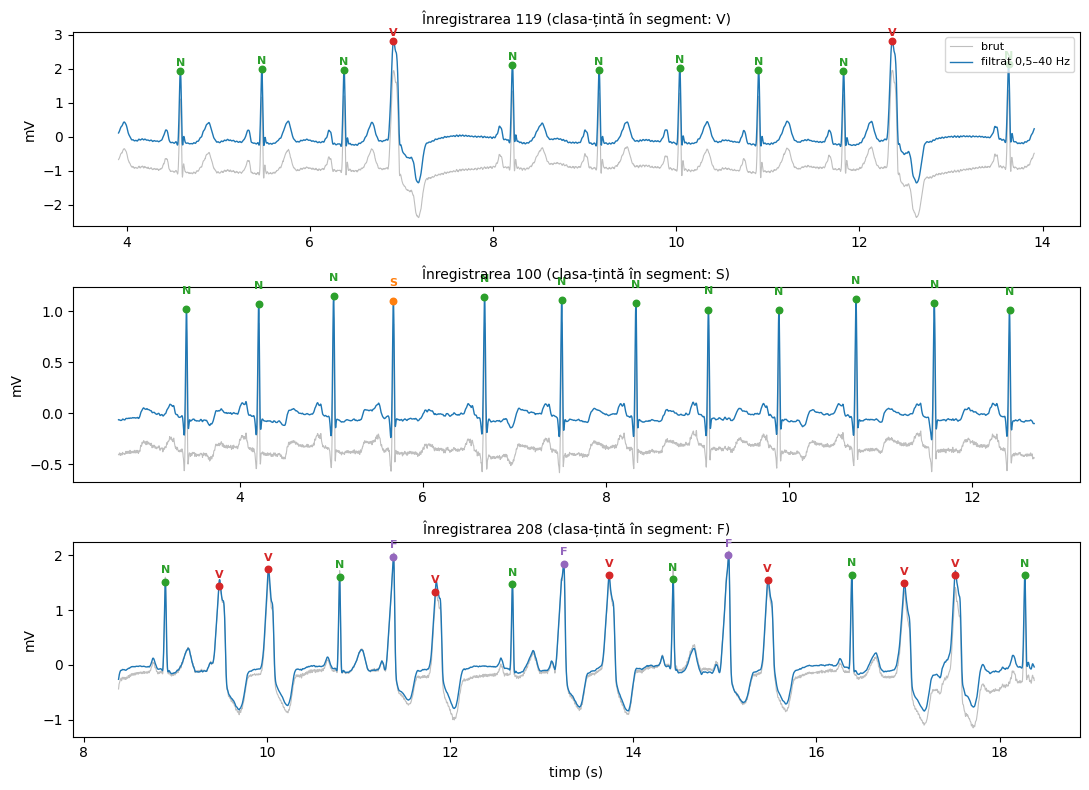

In [5]:
def plot_segment(ax, rec_id, target, before_s=3, length_s=10):
    rec = wfdb.rdrecord(os.path.join(DATA_DIR, rec_id))
    ann = wfdb.rdann(os.path.join(DATA_DIR, rec_id), 'atr')
    names = [n.strip().upper() for n in rec.sig_name]
    sig = rec.p_signal[:, names.index('MLII')]
    sig_f = sosfiltfilt(SOS, sig)
    syms, samp = np.array(ann.symbol), ann.sample
    cand = [i for i, s in enumerate(syms) if AAMI_MAP.get(s) == target and samp[i] > 5 * FS]
    if not cand:
        ax.set_visible(False)
        return
    a = max(0, samp[cand[0]] - before_s * FS)
    b = min(len(sig), a + length_s * FS)
    t = np.arange(a, b) / FS
    ax.plot(t, sig[a:b], color='0.75', lw=0.8, label='brut')
    ax.plot(t, sig_f[a:b], color='C0', lw=1.0, label='filtrat 0,5–40 Hz')
    for i in range(len(samp)):
        if a <= samp[i] < b and syms[i] in AAMI_MAP:
            c = AAMI_MAP[syms[i]]
            ax.scatter(samp[i] / FS, sig_f[samp[i]], color=COL[c], s=22, zorder=3)
            ax.text(samp[i] / FS, sig_f[samp[i]] + 0.15, c, color=COL[c], ha='center', fontsize=8, fontweight='bold')
    ax.set_title(f"Înregistrarea {rec_id} (clasa-țintă în segment: {target})", fontsize=10)
    ax.set_ylabel("mV")


fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=False)
for ax, (rid, tgt) in zip(axes, [('119', 'V'), ('100', 'S'), ('208', 'F')]):
    plot_segment(ax, rid, tgt)
axes[0].legend(loc='upper right', fontsize=8)
axes[-1].set_xlabel("timp (s)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig1_segmente_ecg_adnotari.png", dpi=150)
plt.show()

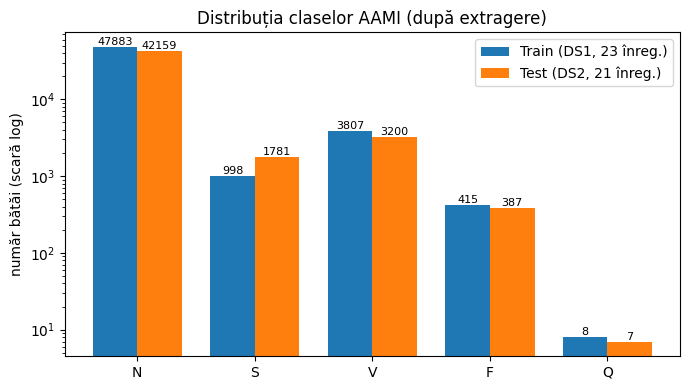

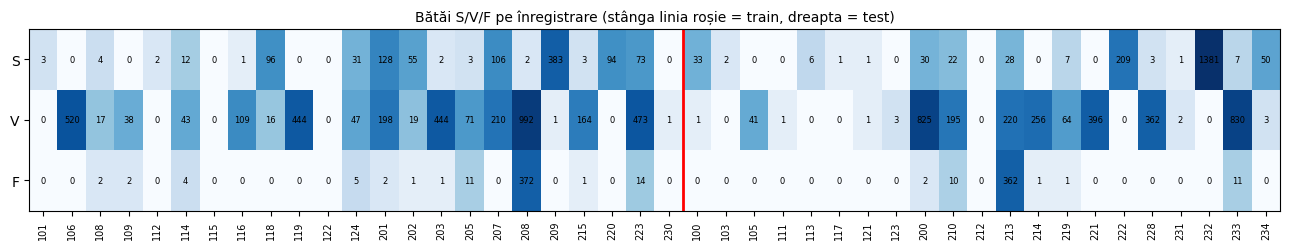

In [6]:
order = ['N', 'S', 'V', 'F', 'Q']
c_tr, c_te = Counter(D_train['y']), Counter(D_test['y'])
x, w = np.arange(len(order)), 0.38
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - w / 2, [c_tr[c] for c in order], w, label='Train (DS1, 23 înreg.)', color='C0')
b2 = ax.bar(x + w / 2, [c_te[c] for c in order], w, label='Test (DS2, 21 înreg.)', color='C1')
ax.set_yscale('log')
ax.bar_label(b1, fmt='%d', fontsize=8)
ax.bar_label(b2, fmt='%d', fontsize=8)
ax.set_xticks(x, order)
ax.set_ylabel("număr bătăi (scară log)")
ax.set_title("Distribuția claselor AAMI (după extragere)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig2_distributie_clase.png", dpi=150)
plt.show()

# distributia pe inregistrari: arata ca S/F sunt concentrate in cateva inregistrari (de aici nevoia de split pe pacient)
recs_all = DS1_TRAIN + DS2_TEST
D_all_y = np.concatenate([D_train['y'], D_test['y']])
D_all_rec = np.concatenate([D_train['rec'], D_test['rec']])
M = np.array([[np.sum((D_all_rec == r) & (D_all_y == c)) for r in recs_all] for c in ['S', 'V', 'F']])
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.imshow(np.log10(1 + M), aspect='auto', cmap='Blues')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, str(M[i, j]), ha='center', va='center', fontsize=6, color='k')
ax.set_yticks(range(3), ['S', 'V', 'F'])
ax.set_xticks(range(len(recs_all)), recs_all, rotation=90, fontsize=7)
ax.axvline(len(DS1_TRAIN) - 0.5, color='r', lw=2)
ax.set_title("Bătăi S/V/F pe înregistrare (stânga linia roșie = train, dreapta = test)", fontsize=10)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig3_clase_pe_inregistrare.png", dpi=150)
plt.show()

## Reprezentările
* **RR** (6): RR precedent, RR următor, raport pre/post, pre/medie locală, post/medie locală, medie locală (ultimele 10 RR, doar trecut).
* **Morfologie QRS** (~28): amplitudini, poziții relative la R, lățime la jumătate de amplitudine, arie/energie QRS, pante, unda T, unda P, statistici ale ferestrei.
* **R1** = RR + morfologie. **R2** = fereastra de 200 de eșantioane filtrată → PCA (95% varianță, *fit doar pe train*; în CV, doar pe fold-ul de antrenare).
* Ambele pornesc de la **același semnal filtrat**, deci diferența vine din reprezentare, nu din preprocesare.

In [7]:
RR_NAMES = ['rr_pre', 'rr_post', 'rr_pre/rr_post', 'rr_pre/loc', 'rr_post/loc', 'rr_loc']


def rr_features(D):
    pre, post, loc = D['rr_pre'], D['rr_post'], D['rr_loc']
    return np.column_stack([pre, post, pre / post, pre / loc, post / loc, loc])


def morph_features(D):
    W = D['filt'].astype(np.float64)
    n = len(W)
    ar = np.arange(n)
    f = {}
    # varful R (cautam extremul in +-10 esantioane in jurul adnotarii)
    j = np.abs(W[:, R_IDX - 10:R_IDX + 11]).argmax(1) + R_IDX - 10
    f['r_amp'] = W[ar, j]
    f['r_off'] = j - R_IDX
    f['w_max'], f['w_min'] = W.max(1), W.min(1)
    f['w_ptp'] = f['w_max'] - f['w_min']
    f['w_argmax'], f['w_argmin'] = W.argmax(1) - R_IDX, W.argmin(1) - R_IDX
    qrs = W[:, R_IDX - 15:R_IDX + 26]
    f['qrs_area'] = np.abs(qrs).sum(1) / FS
    f['qrs_energy'] = (qrs ** 2).sum(1) / FS
    half = 0.5 * np.abs(qrs).max(1, keepdims=True)
    f['qrs_width'] = (np.abs(W[:, R_IDX - 30:R_IDX + 41]) > half).sum(1)
    d = np.diff(W[:, R_IDX - 20:R_IDX + 31], axis=1)
    f['slope_up'], f['slope_down'] = d.max(1), d.min(1)
    t = W[:, R_IDX + 40:]
    f['t_max'], f['t_min'] = t.max(1), t.min(1)
    f['t_amp'] = np.where(np.abs(f['t_max']) >= np.abs(f['t_min']), f['t_max'], f['t_min'])
    p = W[:, :R_IDX - 20]
    f['p_max'], f['p_min'] = p.max(1), p.min(1)
    f['w_mean'], f['w_std'] = W.mean(1), W.std(1)
    f['w_skew'], f['w_kurt'] = skew(W, axis=1), kurtosis(W, axis=1)
    f['qrs_over_t'] = np.abs(f['r_amp']) / (np.abs(f['t_amp']) + 1e-3)
    names = list(f.keys())
    return np.nan_to_num(np.column_stack([f[k] for k in names])), names


FEATURE_SETS = {
    'RR-only':       ('rr',),
    'Morph-only':    ('morph',),
    'R1 (RR+morf.)': ('rr', 'morph'),
    'R2 (PCA)':      ('pca',),
    'R2+RR':         ('pca', 'rr'),
}


def build_features(spec, fit, app):
    """fit = datele pe care se potriveste PCA (doar train/fold-train); app = datele de transformat."""
    Pf, Pa, names = [], [], []
    for kind in spec:
        if kind == 'rr':
            Pf.append(rr_features(fit)); Pa.append(rr_features(app)); names += RR_NAMES
        elif kind == 'morph':
            ff, nm = morph_features(fit); fa, _ = morph_features(app)
            Pf.append(ff); Pa.append(fa); names += nm
        elif kind == 'pca':
            pca = PCA(n_components=PCA_VAR, svd_solver='full', random_state=0).fit(fit['filt'])
            Pf.append(pca.transform(fit['filt'])); Pa.append(pca.transform(app['filt']))
            names += [f'pc{i + 1}' for i in range(pca.n_components_)]
    return np.hstack(Pf), np.hstack(Pa), names

## Protocolul experimental
1. **Split final:** DS1 (23 înreg.) → antrenare; DS2 (21 înreg.) → test, atins o singură dată pentru fiecare model. Fără niciun pacient comun (verificat prin `assert`).
2. **Alegerea reprezentării (fără să ating testul):** CV pe 5 fold-uri **grupate pe pacient** în DS1 (`StratifiedGroupKFold`); PCA se potrivește doar pe fold-ul de antrenare.
3. **Model fix pentru CP2:** Random Forest (100 arbori, `class_weight='balanced_subsample'`, `min_samples_leaf=2`); fără tuning de hiperparametri (rămâne pentru CP3).
4. **Metrici:** Macro-F1 pe N/S/V/F (media claselor cu suport > 0), sensibilitate și +P pe clasă, și triaj binar (anormal = S/V/F): Se și Sp. Acuratețea simplă nu se raportează ca metrică principală (N = 89,5% din bătăi).
5. **Variabilitate:** 5 seed-uri RF pe test (medie ± std) + interval de încredere 95% prin bootstrap **pe pacienți** (se reeșantionează înregistrările).
6. **Baseline-uri:** mereu-N (echivalentul „climatologiei"), aleator stratificat după priorii din train, regulă RR (RR precedent < 0,85 × media locală → anormal; doar pentru triaj).

In [8]:
CIDX = {c: i for i, c in enumerate(CLASSES)}
K = len(CLASSES)
MODEL_KEYS = ['filt', 'y', 'rr_pre', 'rr_post', 'rr_loc', 'rec', 'patient']


def subset(D, mask):
    return {k: D[k][mask] for k in MODEL_KEYS}


def to_int(y):
    return np.array([CIDX[c] for c in y])


def f1_from_cm(cm):
    tp = np.diag(cm).astype(float)
    fn = cm.sum(1) - tp
    fp = cm.sum(0) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0)
    sup = cm.sum(1)
    rec = tp / np.maximum(sup, 1)
    prec = tp / np.maximum(tp + fp, 1)
    return f1, rec, prec, sup


def macro_f1(cm):
    f1, _, _, sup = f1_from_cm(cm)
    return float(f1[sup > 0].mean())


def triage(y_true, pred):
    at, ap = (y_true != 'N'), (pred != 'N')
    se = (at & ap).sum() / max(at.sum(), 1)
    sp = (~at & ~ap).sum() / max((~at).sum(), 1)
    return float(se), float(sp)


def make_rf(seed):
    return RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=2,
                                  class_weight='balanced_subsample', n_jobs=-1, random_state=seed)


keep_tr = (D_train['y'] != 'Q') if EXCLUDE_Q else np.ones(len(D_train['y']), bool)
keep_te = (D_test['y'] != 'Q') if EXCLUDE_Q else np.ones(len(D_test['y']), bool)
Dtr, Dte = subset(D_train, keep_tr), subset(D_test, keep_te)
print(f"Train: {len(Dtr['y'])} bătăi, {len(np.unique(Dtr['patient']))} pacienți | "
      f"Test: {len(Dte['y'])} bătăi, {len(np.unique(Dte['patient']))} pacienți (Q exclus: {EXCLUDE_Q})")

sgkf = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=0)
folds = list(sgkf.split(np.zeros(len(Dtr['y'])), Dtr['y'], Dtr['patient']))
fold_tab = pd.DataFrame(
    [{**{'fold': k, 'pacienți val.': len(np.unique(Dtr['patient'][va]))},
      **{c: int((Dtr['y'][va] == c).sum()) for c in CLASSES}} for k, (tr, va) in enumerate(folds)]
)
for k, (tr, va) in enumerate(folds):
    assert set(Dtr['patient'][tr]).isdisjoint(set(Dtr['patient'][va])), "Leakage de pacient in CV!"
print("\nFold-uri CV (grupate pe pacient) — distribuția claselor în validare:")
print(fold_tab.to_string(index=False))

Train: 53103 bătăi, 22 pacienți | Test: 47527 bătăi, 21 pacienți (Q exclus: True)

Fold-uri CV (grupate pe pacient) — distribuția claselor în validare:
 fold  pacienți val.     N   S    V   F
    0              4  8641  87  961  19
    1              5 10990 388 1102 372
    2              4  6642   7  981   2
    3              5 12125 419  654   9
    4              4  9485  97  109  13


In [9]:
cv_res = {}
t0 = time.time()
for name, spec in FEATURE_SETS.items():
    sc, cm_tot = [], np.zeros((K, K), dtype=int)
    for k, (tr, va) in enumerate(folds):
        Ftr, Fva, _ = build_features(spec, subset(Dtr, tr), subset(Dtr, va))
        clf = make_rf(0).fit(Ftr, Dtr['y'][tr])
        cm = confusion_matrix(Dtr['y'][va], clf.predict(Fva), labels=CLASSES)
        sc.append(macro_f1(cm))
        cm_tot += cm
    cv_res[name] = dict(mean=macro_f1(cm_tot), std=float(np.std(sc)), folds=sc)
    print(f"CV  {name:<16} macro-F1 (out-of-fold unit) = {cv_res[name]['mean']:.3f} | pe fold-uri: {np.round(sc, 3)}")
print(f"CV: {time.time() - t0:.0f} s")

CV  RR-only          macro-F1 (out-of-fold unit) = 0.378 | pe fold-uri: [0.391 0.349 0.34  0.398 0.479]
CV  Morph-only       macro-F1 (out-of-fold unit) = 0.397 | pe fold-uri: [0.414 0.476 0.474 0.305 0.282]
CV  R1 (RR+morf.)    macro-F1 (out-of-fold unit) = 0.448 | pe fold-uri: [0.436 0.481 0.578 0.303 0.55 ]
CV  R2 (PCA)         macro-F1 (out-of-fold unit) = 0.392 | pe fold-uri: [0.373 0.467 0.434 0.325 0.336]
CV  R2+RR            macro-F1 (out-of-fold unit) = 0.449 | pe fold-uri: [0.417 0.475 0.517 0.336 0.567]
CV: 462 s


In [10]:
spec = FEATURE_SETS['R1 (RR+morf.)']
cm_tot = np.zeros((K, K), dtype=int)
for tr, va in folds:
    Ftr, Fva, _ = build_features(spec, subset(Dtr, tr), subset(Dtr, va))
    clf = make_rf(0).fit(Ftr, Dtr['y'][tr])
    cm_tot += confusion_matrix(Dtr['y'][va], clf.predict(Fva), labels=CLASSES)
f1, rc, pr, sup = f1_from_cm(cm_tot)
print(pd.DataFrame({'suport': sup, 'Se': rc.round(3), '+P': pr.round(3), 'F1': f1.round(3)}, index=CLASSES))
print(cm_tot)

   suport     Se     +P     F1
N   47883  0.962  0.967  0.964
S     998  0.073  0.233  0.111
V    3807  0.830  0.628  0.715
F     415  0.000  0.000  0.000
[[46069   214  1537    63]
 [  697    73   225     3]
 [  580    25  3159    43]
 [  305     1   109     0]]


In [11]:
test_res = {}
t0 = time.time()
for name, spec in FEATURE_SETS.items():
    Ftr, Fte, feat_names = build_features(spec, Dtr, Dte)
    r = dict(f1=[], rec=[], prec=[], se=[], sp=[], nfeat=Ftr.shape[1])
    for seed in range(N_SEEDS):
        clf = make_rf(seed).fit(Ftr, Dtr['y'])
        pred = clf.predict(Fte)
        cm = confusion_matrix(Dte['y'], pred, labels=CLASSES)
        _, rc, pr, _ = f1_from_cm(cm)
        se, sp = triage(Dte['y'], pred)
        r['f1'].append(macro_f1(cm)); r['rec'].append(rc); r['prec'].append(pr)
        r['se'].append(se); r['sp'].append(sp)
        if seed == 0:
            r['pred0'] = pred
            r['imp'] = pd.Series(clf.feature_importances_, index=feat_names).sort_values(ascending=False)
    r['rec'], r['prec'] = np.array(r['rec']), np.array(r['prec'])
    test_res[name] = r
    print(f"TEST {name:<16} macro-F1 = {np.mean(r['f1']):.3f} ± {np.std(r['f1']):.3f}  "
          f"(#trăsături = {r['nfeat']})")
print(f"Test: {time.time() - t0:.0f} s")

TEST RR-only          macro-F1 = 0.437 ± 0.003  (#trăsături = 6)
TEST Morph-only       macro-F1 = 0.404 ± 0.005  (#trăsături = 22)
TEST R1 (RR+morf.)    macro-F1 = 0.521 ± 0.008  (#trăsături = 28)
TEST R2 (PCA)         macro-F1 = 0.404 ± 0.002  (#trăsături = 8)
TEST R2+RR            macro-F1 = 0.551 ± 0.015  (#trăsături = 14)
Test: 565 s


In [12]:
base_res = {}
# (a) mereu N
pred = np.full(len(Dte['y']), 'N')
cm = confusion_matrix(Dte['y'], pred, labels=CLASSES)
_, rc, pr, _ = f1_from_cm(cm)
base_res['Majoritar (mereu N)'] = dict(f1=[macro_f1(cm)], rec=np.array([rc]), prec=np.array([pr]),
                                      se=[triage(Dte['y'], pred)[0]], sp=[triage(Dte['y'], pred)[1]])
# (b) aleator stratificat dupa priorii din train
priors = np.array([(Dtr['y'] == c).mean() for c in CLASSES])
f1s, rcs, prs, ses, sps = [], [], [], [], []
for seed in range(N_SEEDS):
    rng = np.random.default_rng(seed)
    pred = rng.choice(CLASSES, size=len(Dte['y']), p=priors)
    cm = confusion_matrix(Dte['y'], pred, labels=CLASSES)
    _, rc, pr, _ = f1_from_cm(cm)
    f1s.append(macro_f1(cm)); rcs.append(rc); prs.append(pr)
    se, sp = triage(Dte['y'], pred); ses.append(se); sps.append(sp)
base_res['Aleator stratificat'] = dict(f1=f1s, rec=np.array(rcs), prec=np.array(prs), se=ses, sp=sps)
# (c) regula RR (doar triaj binar): bataie prematura = RR precedent < 0.85 * media locala
pred = np.where(Dte['rr_pre'] < 0.85 * Dte['rr_loc'], 'V', 'N')
se, sp = triage(Dte['y'], pred)
base_res['Regulă RR (doar triaj)'] = dict(f1=None, se=[se], sp=[sp])
for k, v in base_res.items():
    f = f"{np.mean(v['f1']):.3f}" if v['f1'] is not None else "—"
    print(f"{k:<26} macro-F1 = {f:>6}   triaj Se = {np.mean(v['se']):.3f}  Sp = {np.mean(v['sp']):.3f}")

Majoritar (mereu N)        macro-F1 =  0.235   triaj Se = 0.000  Sp = 1.000
Aleator stratificat        macro-F1 =  0.249   triaj Se = 0.100  Sp = 0.901
Regulă RR (doar triaj)     macro-F1 =      —   triaj Se = 0.758  Sp = 0.966


                Metodă  #trăs. CV macro-F1 (DS1) Test macro-F1          Se S          Se V          Se F          +P S          +P V          +P F      Triaj Se      Triaj Sp
          RF + RR-only       6     0.378 ± 0.049 0.437 ± 0.003 0.076 ± 0.008 0.731 ± 0.003 0.005 ± 0.000 0.163 ± 0.016 0.629 ± 0.005 0.008 ± 0.000 0.647 ± 0.003 0.969 ± 0.000
       RF + Morph-only      22     0.397 ± 0.082 0.404 ± 0.005 0.000 ± 0.000 0.813 ± 0.001 0.013 ± 0.011 0.000 ± 0.000 0.548 ± 0.020 0.022 ± 0.015 0.545 ± 0.003 0.951 ± 0.004
    RF + R1 (RR+morf.)      28     0.448 ± 0.097 0.521 ± 0.008 0.038 ± 0.007 0.894 ± 0.004 0.200 ± 0.019 0.433 ± 0.064 0.844 ± 0.008 0.161 ± 0.018 0.615 ± 0.002 0.983 ± 0.001
         RF + R2 (PCA)       8     0.392 ± 0.055 0.404 ± 0.002 0.008 ± 0.002 0.870 ± 0.009 0.000 ± 0.000 0.024 ± 0.007 0.540 ± 0.006 0.000 ± 0.000 0.559 ± 0.006 0.933 ± 0.005
            RF + R2+RR      14     0.449 ± 0.080 0.551 ± 0.015 0.120 ± 0.015 0.957 ± 0.002 0.114 ± 0.038 0.420 ± 0.039 0.782 

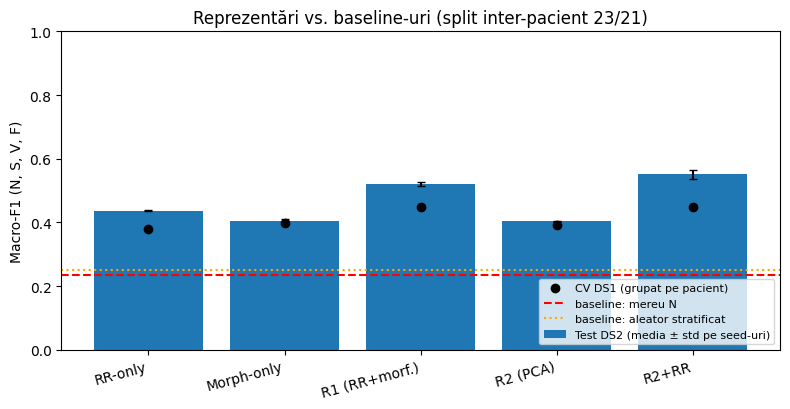

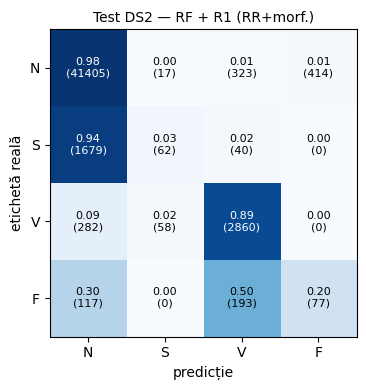


PCA (fit pe train): 8 componente explică 0.956 din varianță


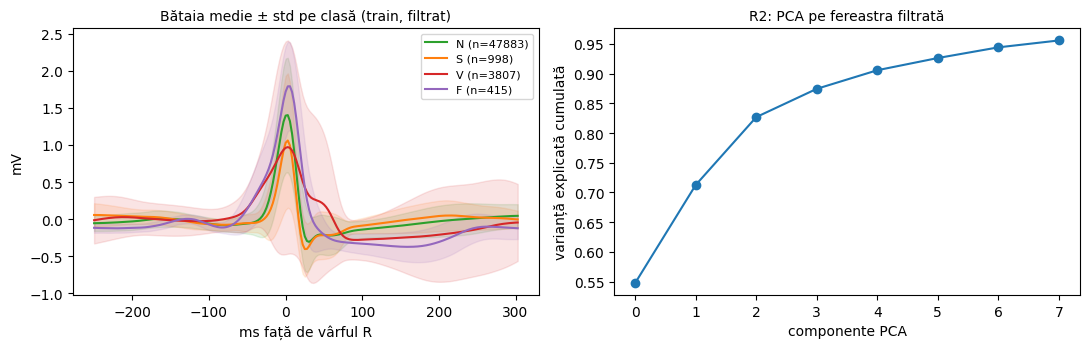

In [13]:
def ms(a, d=3):
    a = np.asarray(a, float)
    return f"{a.mean():.{d}f} ± {a.std():.{d}f}"


iS, iV, iF = CLASSES.index('S'), CLASSES.index('V'), CLASSES.index('F')
rows = []
for name in FEATURE_SETS:
    t, c = test_res[name], cv_res[name]
    rows.append({'Metodă': f"RF + {name}", '#trăs.': t['nfeat'],
                 'CV macro-F1 (DS1)': f"{c['mean']:.3f} ± {c['std']:.3f}",
                 'Test macro-F1': ms(t['f1']),
                 'Se S': ms(t['rec'][:, iS]), 'Se V': ms(t['rec'][:, iV]), 'Se F': ms(t['rec'][:, iF]),
                 '+P S': ms(t['prec'][:, iS]), '+P V': ms(t['prec'][:, iV]), '+P F': ms(t['prec'][:, iF]),
                 'Triaj Se': ms(t['se']), 'Triaj Sp': ms(t['sp'])})
for name, b in base_res.items():
    has = b['f1'] is not None
    rows.append({'Metodă': name, '#trăs.': 0, 'CV macro-F1 (DS1)': '—',
                 'Test macro-F1': ms(b['f1']) if has else '—',
                 'Se S': ms(b['rec'][:, iS]) if has else '—', 'Se V': ms(b['rec'][:, iV]) if has else '—',
                 'Se F': ms(b['rec'][:, iF]) if has else '—',
                 '+P S': ms(b['prec'][:, iS]) if has else '—', '+P V': ms(b['prec'][:, iV]) if has else '—',
                 '+P F': ms(b['prec'][:, iF]) if has else '—',
                 'Triaj Se': ms(b['se']), 'Triaj Sp': ms(b['sp'])})
results_df = pd.DataFrame(rows)
pd.set_option('display.width', 250)
print(results_df.to_string(index=False))
results_df.to_csv(f"{OUT_DIR}/results_cp2.csv", index=False)

# reprezentarea aleasa = cea mai buna dupa CV (nu dupa test)
best = 'R1 (RR+morf.)'  # ales după CV, înainte de test (egalitate cu R2+RR; criteriu: interpretabilitate))
print(f"\nReprezentare aleasă după CV (DS1): {best}")


def bootstrap_ci(y_true, pred, recs, n_boot, seed=0):
    yt, yp = to_int(y_true), to_int(pred)
    urec = np.unique(recs)
    cms = np.stack([np.bincount(yt[recs == r] * K + yp[recs == r], minlength=K * K).reshape(K, K) for r in urec])
    rng = np.random.default_rng(seed)
    vals = [macro_f1(cms[rng.integers(0, len(urec), len(urec))].sum(0)) for _ in range(n_boot)]
    return np.percentile(vals, [2.5, 97.5])


lo, hi = bootstrap_ci(Dte['y'], test_res[best]['pred0'], Dte['rec'], N_BOOT)
print(f"Bootstrap pe pacienți ({N_BOOT}x), {best}, seed 0: macro-F1 95% CI = [{lo:.3f}, {hi:.3f}]")
for n in FEATURE_SETS:
    if n != best:
        l2, h2 = bootstrap_ci(Dte['y'], test_res[n]['pred0'], Dte['rec'], N_BOOT)
        print(f"   (pentru comparație) {n:<16} CI = [{l2:.3f}, {h2:.3f}]")

print("\nTop 8 trăsături (importanță RF, seed 0) pentru", best)
print(test_res[best]['imp'].head(8).round(3).to_string())

# --- figura de rezultate
names = list(FEATURE_SETS)
fig, ax = plt.subplots(figsize=(8, 4.2))
xs = np.arange(len(names))
ax.bar(xs, [np.mean(test_res[n]['f1']) for n in names], yerr=[np.std(test_res[n]['f1']) for n in names],
       capsize=3, color='C0', label='Test DS2 (media ± std pe seed-uri)')
ax.scatter(xs, [cv_res[n]['mean'] for n in names], color='k', zorder=3, label='CV DS1 (grupat pe pacient)')
ax.axhline(np.mean(base_res['Majoritar (mereu N)']['f1']), color='r', ls='--', label='baseline: mereu N')
ax.axhline(np.mean(base_res['Aleator stratificat']['f1']), color='orange', ls=':', label='baseline: aleator stratificat')
ax.set_xticks(xs, names, rotation=15, ha='right')
ax.set_ylabel("Macro-F1 (N, S, V, F)")
ax.set_ylim(0, 1)
ax.set_title("Reprezentări vs. baseline-uri (split inter-pacient 23/21)")
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig4_rezultate_reprezentari.png", dpi=150)
plt.show()

# --- matrice de confuzie normalizata pentru reprezentarea aleasa
cm = confusion_matrix(Dte['y'], test_res[best]['pred0'], labels=CLASSES)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha='center', va='center', fontsize=8,
                color='w' if cmn[i, j] > 0.5 else 'k')
ax.set_xticks(range(K), CLASSES); ax.set_yticks(range(K), CLASSES)
ax.set_xlabel("predicție"); ax.set_ylabel("etichetă reală")
ax.set_title(f"Test DS2 — RF + {best}", fontsize=10)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig5_confuzie_{best.split()[0].replace('+', '_')}.png", dpi=150)
plt.show()

# --- bataia medie pe clasa + varianta explicata PCA
pca_full = PCA(n_components=PCA_VAR, svd_solver='full', random_state=0).fit(Dtr['filt'])
print(f"\nPCA (fit pe train): {pca_full.n_components_} componente explică {pca_full.explained_variance_ratio_.sum():.3f} din varianță")
tt = (np.arange(WIN_BEFORE + WIN_AFTER) - R_IDX) / FS * 1000
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for c in CLASSES:
    W = Dtr['filt'][Dtr['y'] == c]
    axs[0].plot(tt, W.mean(0), color=COL[c], label=f"{c} (n={len(W)})")
    axs[0].fill_between(tt, W.mean(0) - W.std(0), W.mean(0) + W.std(0), color=COL[c], alpha=0.12)
axs[0].set_xlabel("ms față de vârful R"); axs[0].set_ylabel("mV"); axs[0].legend(fontsize=8)
axs[0].set_title("Bătaia medie ± std pe clasă (train, filtrat)", fontsize=10)
axs[1].plot(np.cumsum(pca_full.explained_variance_ratio_), marker='o')
axs[1].set_xlabel("componente PCA"); axs[1].set_ylabel("varianță explicată cumulată")
axs[1].set_title("R2: PCA pe fereastra filtrată", fontsize=10)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig6_bataie_medie_pca.png", dpi=150)
plt.show()

In [14]:
summary = {
    'split': {'train_records': len(DS1_TRAIN), 'test_records': len(DS2_TEST),
              'train_beats_used': int(len(Dtr['y'])), 'test_beats_used': int(len(Dte['y'])), 'Q_excluded': EXCLUDE_Q},
    'config': {'n_trees': N_TREES, 'n_seeds': N_SEEDS, 'cv_folds': CV_FOLDS, 'pca_var': PCA_VAR, 'band_hz': BAND},
    'cv_macro_f1': {n: {'mean': cv_res[n]['mean'], 'std': cv_res[n]['std']} for n in FEATURE_SETS},
    'test_macro_f1': {n: {'mean': float(np.mean(test_res[n]['f1'])), 'std': float(np.std(test_res[n]['f1']))} for n in FEATURE_SETS},
    'best_by_cv': best, 'best_bootstrap_ci95': [float(lo), float(hi)],
}
with open(f"{OUT_DIR}/summary_cp2.json", "w") as fh:
    json.dump(summary, fh, indent=2, ensure_ascii=False)
print(json.dumps(summary, indent=2, ensure_ascii=False))

if os.path.isdir('/content/drive/MyDrive'):
    dst = '/content/drive/MyDrive/IC3_CP2_outputs'
    shutil.copytree(OUT_DIR, dst, dirs_exist_ok=True)
    print("Copiat în Drive:", dst)
print("Fișiere:", sorted(os.listdir(OUT_DIR)))

{
  "split": {
    "train_records": 23,
    "test_records": 21,
    "train_beats_used": 53103,
    "test_beats_used": 47527,
    "Q_excluded": true
  },
  "config": {
    "n_trees": 100,
    "n_seeds": 5,
    "cv_folds": 5,
    "pca_var": 0.95,
    "band_hz": [
      0.5,
      40.0
    ]
  },
  "cv_macro_f1": {
    "RR-only": {
      "mean": 0.3780069659873446,
      "std": 0.049322923405150876
    },
    "Morph-only": {
      "mean": 0.39713061612060874,
      "std": 0.08222603572150912
    },
    "R1 (RR+morf.)": {
      "mean": 0.4476915820336373,
      "std": 0.09740004249590423
    },
    "R2 (PCA)": {
      "mean": 0.3923815529671214,
      "std": 0.05541233261501743
    },
    "R2+RR": {
      "mean": 0.44908683130274496,
      "std": 0.08004653425170827
    }
  },
  "test_macro_f1": {
    "RR-only": {
      "mean": 0.43718271130368314,
      "std": 0.00308599948505163
    },
    "Morph-only": {
      "mean": 0.4044193869438934,
      "std": 0.0054216096479947976
    },
    "R1